In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'CSAN3.SA'
papeis_adicionais = ['RAIZ4.SA', 'RAIL3.SA', 'VALE3.SA', 'SMTO3.SA', 'JALL3.SA', 'PETR4.SA', 'PRIO3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[CSAN3.SA] Cache existente cobre de 2020-01-02 a 2025-07-11.
[CSAN3.SA] Cache cobre período solicitado (2023-01-23 a 2025-07-11).
[CSAN3.SA] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[CSAN3.SA] Últimos dias atualizados em memória com sucesso.
[CSAN3.SA] Retornando 615 linhas para o período solicitado.
✅ Usando cache local: /palpiteiro/dados\macro_20220123_20250712.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-07-11.
[^BVSP] Cache cobre período solicitado (2023-01-23 a 2025-07-11).
[^BVSP] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[^BVSP] Últimos dias atualizados em memória com sucesso.
[^BVSP] Retornando 615 linhas para o período solicitado.
[BOVA11.SA] Cache existente cob

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-30,6.72,6.89,6.69,6.86,6.86,17146700,0.017804,0.038900,35.005327,-0.289302,-0.133730,-0.155572,0.20,0.319025,0.046505,0.029154,6.898,7.7575,15.0,0.26,5.4571,136865.0000,139103.000,136430.0000,138855.000000,138855.000000,4715665
2025-07-01,6.89,7.13,6.86,7.07,7.07,18957400,0.030612,0.037584,40.103310,-0.286368,-0.164258,-0.122110,0.27,0.315524,0.044629,0.038190,6.890,7.7085,15.0,0.26,5.4511,138855.0000,139695.000,138855.0000,139549.000000,139549.000000,2903180
2025-07-02,7.09,7.14,6.92,6.93,6.93,12153600,-0.019802,0.036889,37.965337,-0.291973,-0.189801,-0.102172,0.22,0.308701,0.044546,0.031746,6.902,7.6280,15.0,0.26,5.4512,139586.0000,140049.000,138384.0000,139051.000000,139051.000000,3619807
2025-07-03,6.96,7.13,6.90,7.07,7.07,11832700,0.020202,0.038543,41.333528,-0.281869,-0.208214,-0.073655,0.23,0.303079,0.042868,0.032532,6.934,7.5660,15.0,0.26,5.4208,139051.0000,141304.000,139051.0000,140928.000000,140928.000000,3879378
2025-07-04,7.05,7.17,7.00,7.14,7.14,5731700,0.009901,0.027257,42.999966,-0.265157,-0.219603,-0.045554,0.17,0.293573,0.041117,0.023810,7.014,7.5210,15.0,0.26,5.4090,140928.0000,141537.000,140597.0000,141478.000000,141478.000000,5528911
2025-07-07,7.15,7.18,6.90,6.90,6.90,13279000,-0.033613,0.025078,38.918173,-0.268187,-0.229320,-0.038867,0.28,0.292604,0.042406,0.040580,7.022,7.4630,15.0,0.26,5.4552,141265.0000,141342.000,139295.0000,139490.000000,139490.000000,3691359
2025-07-08,6.91,6.95,6.80,6.89,6.89,12234100,-0.001449,0.023522,38.753101,-0.268303,-0.237116,-0.031186,0.15,0.282418,0.040990,0.021771,6.986,7.4070,15.0,0.26,5.4571,139491.0000,139591.000,138770.0000,139303.000000,139303.000000,2574588
2025-07-09,6.86,6.89,6.61,6.61,6.61,14897100,-0.040639,0.024601,34.358789,-0.287671,-0.247227,-0.040444,0.28,0.282245,0.042700,0.042360,6.922,7.3245,15.0,0.26,5.4626,139303.0000,139331.000,137299.0000,137481.000000,137481.000000,8538960
2025-07-10,6.48,6.50,6.33,6.41,6.41,26659800,-0.030257,0.025691,31.602273,-0.315523,-0.260886,-0.054636,0.28,0.282085,0.044007,0.043682,6.790,7.2325,15.0,0.26,5.5433,137472.0000,137472.000,136015.0000,136743.000000,136743.000000,5335029


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-30,0.319025,0.046505,0.20,0.029154
2025-07-01,0.315524,0.044629,0.27,0.038190
2025-07-02,0.308701,0.044546,0.22,0.031746
2025-07-03,0.303079,0.042868,0.23,0.032532
2025-07-04,0.293573,0.041117,0.17,0.023810
2025-07-07,0.292604,0.042406,0.28,0.040580
2025-07-08,0.282418,0.040990,0.15,0.021771
2025-07-09,0.282245,0.042700,0.28,0.042360
2025-07-10,0.282085,0.044007,0.28,0.043682


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 4.30%
Valorização sugerida: 6.45%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.07
stop_loss = 0.05
DIAS_FUTURO = 7  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

#0.0    0.789474
#1.0    0.210526

Target
0.0    0.822368
1.0    0.177632
Name: proportion, dtype: float64

In [11]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
lista_f1_treino = []
lista_f1_validacao = []
lista_pr_auc_treino = []
lista_pr_auc_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    lista_f1_treino.append(f1_score_treino)
    lista_f1_validacao.append(f1_score_validacao)

    lista_pr_auc_treino.append(pr_auc_treino)
    lista_pr_auc_validacao.append(pr_auc_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': lista_f1_treino,
    'F1 Validação': lista_f1_validacao,
    'PR AUC Treino': lista_pr_auc_treino,
    'PR AUC Validação': lista_pr_auc_validacao
})

INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.683
AUC na validação: 0.515
Diferença AUC (Treino - Validação): 0.167
PROVÁVEL OVERFITTING
PR AUC no treino: 0.410
PR AUC na validação: 0.429
Diferença PR AUC (Treino - Validação): -0.019
F1 Score no treino: 0.324
F1 Score na validação: 0.403
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.764
AUC na validação: 0.471
Diferença AUC (Treino - Validação): 0.294
PROVÁVEL OVERFITTING
PR AUC no treino: 0.500
PR AUC na validação: 0.438
Diferença PR AUC (Treino - Validação): 0.062
F1 Score no treino: 0.350
F1 Score na validação: 0.390
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.646
AUC na validação: 0.510
Diferença AUC (Treino - Validação): 0.136
PROVÁVEL OVERFITTING
PR AUC no treino: 0.411
PR AUC na validação: 0.504
Diferença PR AUC (Treino - Validação): -0.093
F1 Score no treino: 0.326
F1 Score na validação: 0.395


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.633
AUC na validação: 0.646
Diferença AUC (Treino - Validação): -0.013
PR AUC no treino: 0.390
PR AUC na validação: 0.603
Diferença PR AUC (Treino - Validação): -0.213
F1 Score no treino: 0.302
F1 Score na validação: 0.605


In [12]:
df_resultados.sort_values(by='PR AUC Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação,PR AUC Treino,PR AUC Validação
5,60,0.301670,0.605328,0.389973,0.603054
4,30,0.325975,0.394661,0.410528,0.503651
1,10,0.349994,0.390077,0.499900,0.437812
0,6,0.324094,0.403436,0.410058,0.428917
2,15,0.310922,0.268651,0.517382,0.345426
3,20,0.347097,0.322746,0.448777,0.331132


In [13]:
# Preparar X e y para treino
DIAS_JANELA_X = 10  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [14]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['retorno_acumulado', 'macd_signal_std', 'ibov_amplitude', 'dias_queda_pct', 'close_max', 'macd_ultimo_norm_atr_principal', 'macd_hist_ultimo', 'macd_ultimo', 'close_min', 'close_amplitude', 'macd_std', 'close_amplitude_norm_atr_principal', 'macd_signal_ultimo', 'macd_mean']
Colunas restantes após filtragem: 51


In [15]:
X_train.tail()

,close_mean,close_std,close_trend,retorno_desde_mudanca_close,close_dist_min,close_ult_vs_mm_janela,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,dias_alta_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_signal_mean,macd_hist_mean,macd_hist_std,tr_mean,tr_std,tr_ultimo,tr_pct_mean,tr_pct_std,tr_pct_ultimo,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,atr_ultimo,macd_std_norm_atr_principal,macd_signal_std_norm_atr_principal,macd_signal_ultimo_norm_atr_principal,macd_hist_std_norm_atr_principal,macd_hist_ultimo_norm_atr_principal,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,close_std_norm_atr_principal
2025-02-12,7.590,0.246306,-0.066182,0.000000,0.13,-0.280,-0.050094,-0.034761,-0.001591,0.039720,0.5,0.030190,-0.033372,22212320.0,8.349387e+06,3.358230e+05,0.533536,0.046544,40.965002,2.976341,39.360481,-0.351597,0.040566,0.016336,0.335,0.124477,0.44,0.044206,0.016400,0.060192,13.25,0.16,5.7711,-0.012662,0.046207,-0.001332,-139.218182,812.778780,0.000000,0.823227,2.892135,-0.003570,0.340238,0.059685,0.089154,-0.926683,0.048013,0.063514,0.365852,1.293214,0.723923
2025-02-13,7.509,0.216972,-0.057030,-0.012312,0.04,-0.289,-0.053115,-0.037115,-0.010175,0.029691,0.4,0.019355,-0.029862,20814640.0,7.664615e+06,7.637770e+05,-0.132548,0.045143,40.162847,2.472259,38.093927,-0.342403,0.036773,0.018094,0.292,0.107373,0.14,0.039047,0.015104,0.019391,13.25,0.16,5.7788,-0.007885,0.032686,0.000000,-104.921212,728.623695,0.000000,0.792257,2.630583,-0.004398,0.325935,0.042580,0.080754,-0.957743,0.055515,0.038419,0.329430,0.429535,0.665690
2025-02-14,7.493,0.203527,-0.037758,0.000000,0.40,0.087,-0.001844,-0.022649,-0.001578,0.033544,0.5,0.025457,-0.028612,21481550.0,7.810067e+06,9.478685e+05,0.210406,0.043980,40.565322,3.003713,45.630332,-0.333761,0.034569,0.017072,0.300,0.114891,0.43,0.040197,0.016036,0.056728,13.25,0.16,5.7283,-0.009086,0.035952,0.000000,86.278788,1123.122413,0.026984,0.866577,2.360602,-0.007437,0.333368,0.038495,0.068027,-0.912398,0.051210,0.095960,0.344638,1.289866,0.610518
2025-02-17,7.491,0.200247,-0.001636,0.026385,0.60,0.289,0.023550,-0.014866,0.000286,0.034620,0.5,0.029183,-0.028612,23338870.0,8.463308e+06,1.260061e+06,0.468469,0.046583,41.212388,4.061487,49.321529,-0.325189,0.034290,0.016612,0.350,0.177576,0.74,0.046632,0.023160,0.095116,13.25,0.16,5.7105,-0.007451,0.028606,-0.003107,276.672727,1507.751973,0.032191,0.851718,2.448403,-0.006131,0.362413,0.065861,0.058947,-0.799230,0.045837,0.160181,0.489982,2.041867,0.552538
2025-02-18,7.500,0.211398,0.026182,0.000000,0.59,0.270,0.022099,-0.009208,0.001696,0.034195,0.5,0.029183,-0.025792,24478370.0,7.284873e+06,3.717194e+05,-0.089919,0.045425,42.029666,4.767940,49.141879,-0.316224,0.035857,0.019543,0.354,0.173986,0.23,0.047118,0.022696,0.029601,13.25,0.16,5.6979,-0.009652,0.034654,-0.005307,358.678788,1668.002385,0.000000,0.874867,2.409701,-0.002158,0.352955,0.105593,0.066289,-0.768695,0.055370,0.207806,0.492940,0.651641,0.598936


# LogisticRegression

In [16]:
modelo_rl = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', C=0.001)
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.767
AUC na validação: 0.471
Diferença AUC (Treino - Validação): 0.296
PROVÁVEL OVERFITTING
PR AUC no treino: 0.504
PR AUC na validação: 0.438
Diferença PR AUC (Treino - Validação): 0.066
F1 Score no treino: 0.358
F1 Score na validação: 0.390


(np.float64(0.7665114873641736),
 np.float64(0.4705008867119829),
 np.float64(0.2960106006521907),
 np.float64(0.5039038703096643),
 np.float64(0.43781209574461166),
 np.float64(0.35757749363157654),
 np.float64(0.3900774652678178))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 8e3b3c0ced924726b7e7365f313573f3 para CSAN3.SA_10dias_x_0.07val_7dias_alvo
AUC no treino: 0.620
AUC na validação: 0.420

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.767
  Precisão média (em 455 janelas com previsão positiva): 0.274
  Recall médio: 0.487

Calibrando thresholds para precisão mínima de 0.70...
Nenhum threshold atendeu à precisão mínima de 0.70. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.399
Recall médio: 0.426
Sinais de compra presentes na vallidação: 28.0
Sinais de compra previstos na validação: 40
Modelo CSAN3.SA_10dias_x_0.07val_7dias_alvo salvo na run 8e3b3c0ced924726b7e7365f313573f3


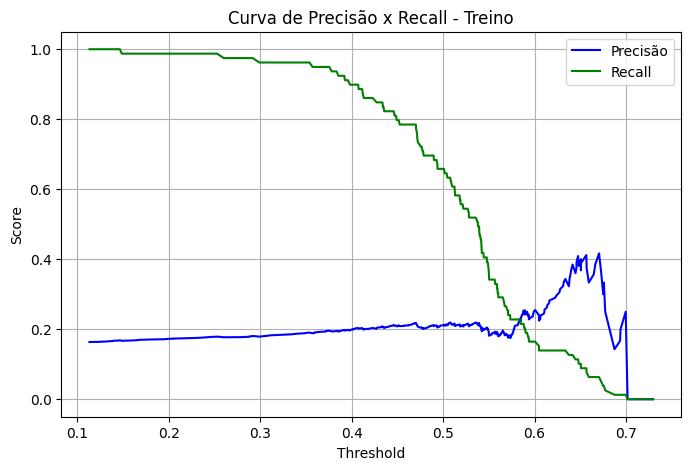

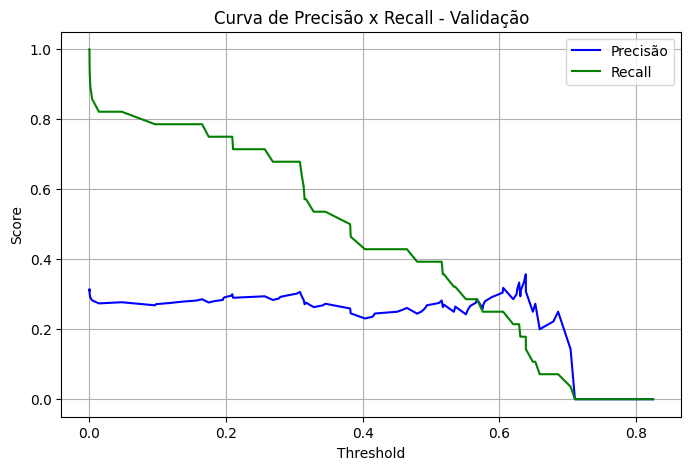

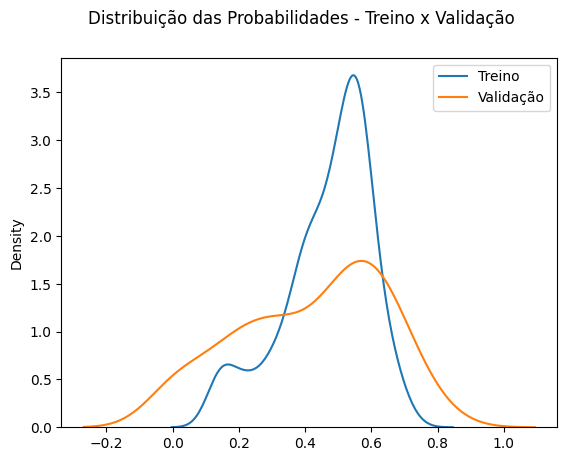

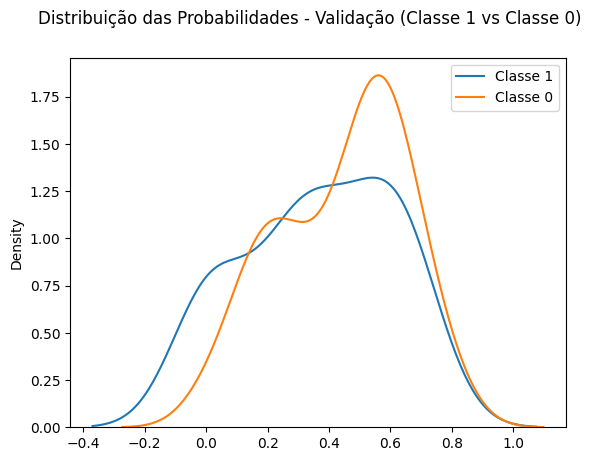

In [17]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [18]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
20,rsi_ultimo,0.000943,0.000943
36,ibov_trend,-0.000932,0.000932
18,rsi_mean,0.000581,0.000581
30,selic_ultimo,0.000450,0.000450
37,ibov_std,-0.000406,0.000406
19,rsi_std,0.000265,0.000265
0,close_mean,0.000135,0.000135
32,dolar_ultimo,0.000053,0.000053
40,beta_papel_ibov,-0.000050,0.000050
4,close_dist_min,0.000029,0.000029


In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k)['Feature'].tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2})
            modelo.fit(X_train[colunas_selecionadas], y_train )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, df_importancias)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


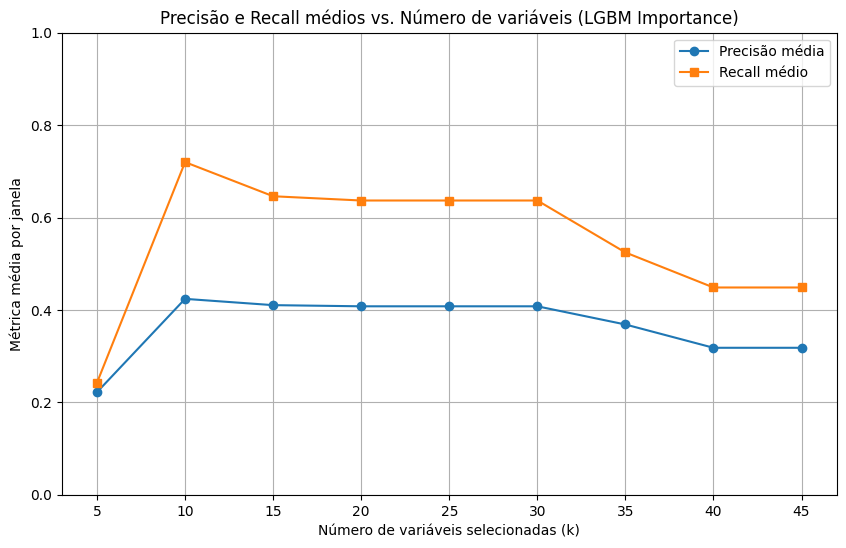

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [25]:
n_features = 30
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['rsi_ultimo',
 'ibov_trend',
 'rsi_mean',
 'selic_ultimo',
 'ibov_std',
 'rsi_std',
 'close_mean',
 'dolar_ultimo',
 'beta_papel_ibov',
 'close_dist_min',
 'close_ult_vs_mm_janela',
 'tr_mean',
 'atr_ultimo',
 'macd_hist_ultimo_norm_atr_principal',
 'macd_signal_mean',
 'tr_ultimo',
 'macd_signal_ultimo_norm_atr_principal',
 'tr_ultimo_norm_atr_principal',
 'close_trend',
 'macd_signal_std_norm_atr_principal',
 'close_std',
 'macd_hist_mean',
 'macd_hist_std_norm_atr_principal',
 'close_std_norm_atr_principal',
 'macd_hist_std',
 'tr_std',
 'macd_std_norm_atr_principal',
 'close_vs_mm20',
 'dias_alta_pct',
 'dolar_trend']

In [26]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [27]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.716
AUC na validação: 0.491
Diferença AUC (Treino - Validação): 0.225
PROVÁVEL OVERFITTING
PR AUC no treino: 0.508
PR AUC na validação: 0.399
Diferença PR AUC (Treino - Validação): 0.109
F1 Score no treino: 0.412
F1 Score na validação: 0.537


(np.float64(0.7161286553270275),
 np.float64(0.4912638632695808),
 np.float64(0.2248647920574467),
 np.float64(0.5079867563536535),
 np.float64(0.3990728863006694),
 np.float64(0.4120553986720636),
 np.float64(0.5368486570249914))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 14cf0efb01aa4bfea9366f639db9d34c para CSAN3.SA_10dias_x_0.07val_7dias_alvo
AUC no treino: 0.828
AUC na validação: 0.415

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.716
  Precisão média (em 425 janelas com previsão positiva): 0.309
  Recall médio: 0.458

Calibrando thresholds para precisão mínima de 0.70...

Threshold Ideal Selecionado: 0.67
  Precisão Média Esperada: 74.65%
  Recall Médio Esperado: 17.61%
  Janelas Usadas para Precisão: 180.0

Threshold ideal baseado em mínimo recall ou precisão: 0.67

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.401
Recall médio: 0.569
Sinais de compra presentes na vallidação: 28.0
Sinais de compra previstos na validação: 56
Modelo CSAN3.SA_10dias_x_

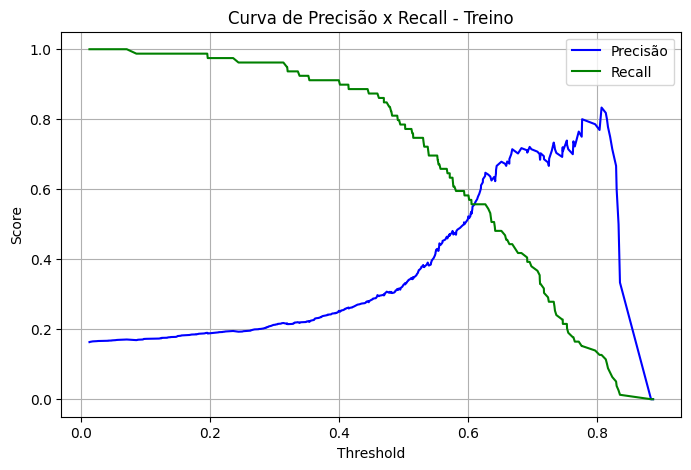

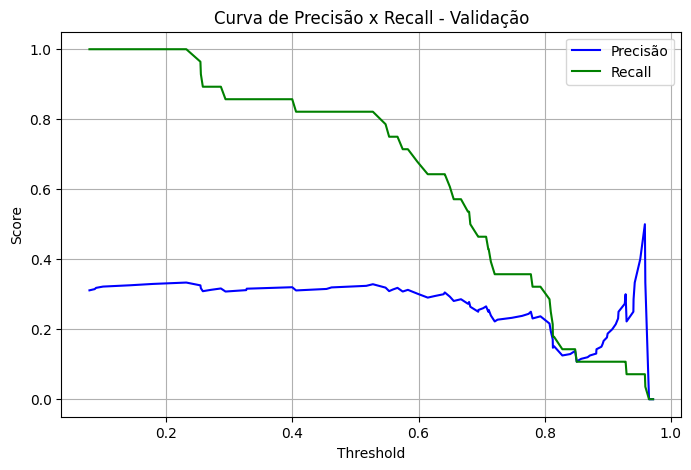

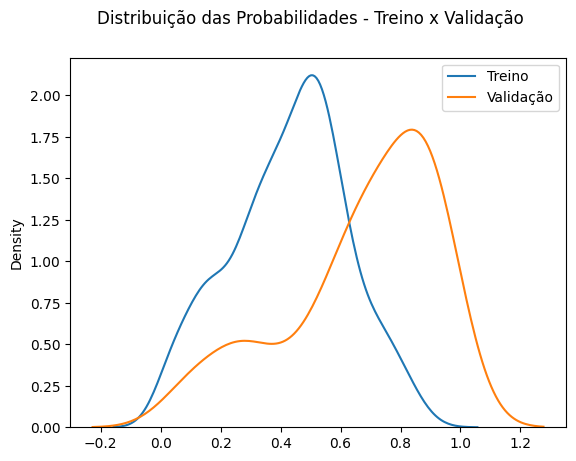

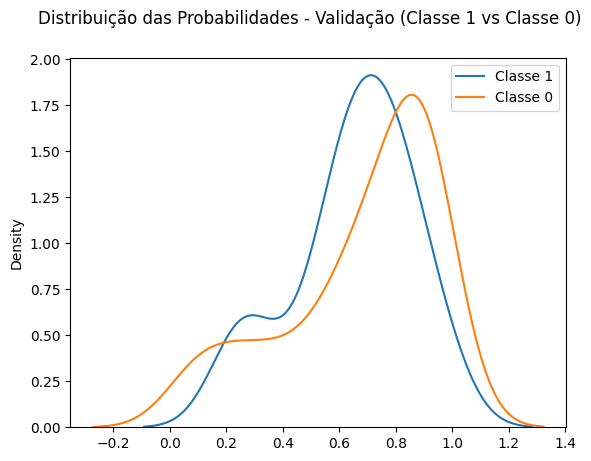

In [28]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [ ]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    #, class_weight={0:2.5, 1:1} # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[13]	valid_0's auc: 0.714286	valid_0's binary_logloss: 0.635803
Treinamento LGBM concluído. Melhor iteração: 13

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.786
AUC na validação: 0.527
Diferença AUC (Treino - Validação): 0.260
PROVÁVEL OVERFITTING
PR AUC no treino: 0.467
PR AUC na validação: 0.435
Diferença PR AUC (Treino - Validação): 0.032
F1 Score no treino: 0.475
F1 Score na validação: 0.215


(np.float64(0.7862949773380108),
 np.float64(0.526668508748471),
 np.float64(0.25962646858953975),
 np.float64(0.46680228409528235),
 np.float64(0.43495651913598127),
 np.float64(0.47525495314198424),
 np.float64(0.21450849721612944))

Avaliar e logar modelo
MLflow Run ID: a3aa057e85394ce7accf3a2f66f0459c para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.768
AUC na validação: 0.572

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.786
  Precisão média (em 453 janelas com previsão positiva): 0.369
  Recall médio: 0.853

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 28 janelas com previsão positiva): 0.858
Recall médio: 0.174
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 15
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run a3aa057e85394ce7accf3a2f66f0459c


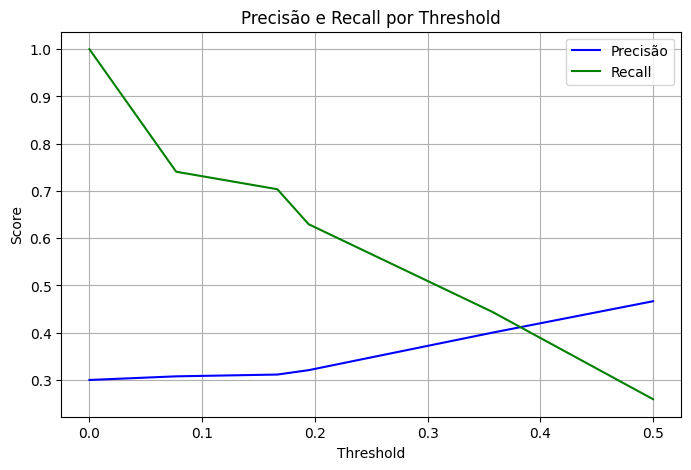

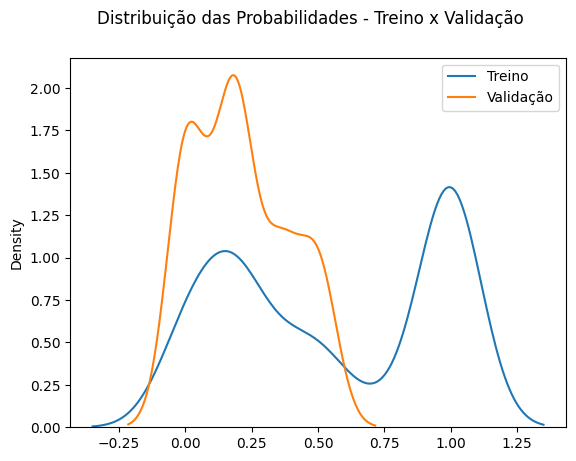

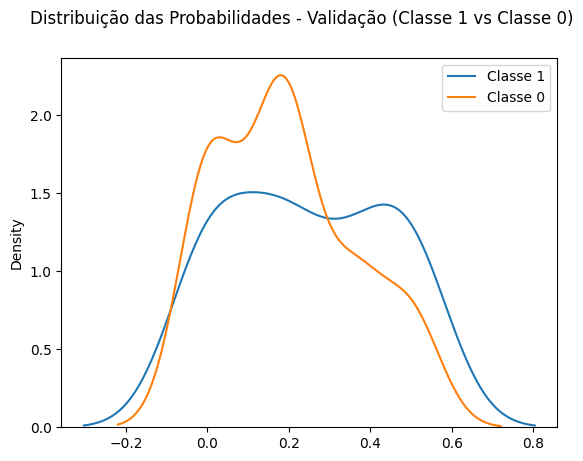

In [ ]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

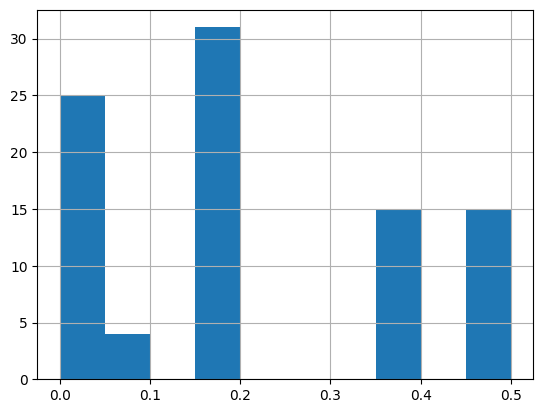

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [ ]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_vs_adc_close_mean_geral            593.602402
adc_correl_com_principal_BEEF3           301.161100
dolar_trend                              168.918600
close_amplitude_norm_atr_principal        90.541520
adc_correl_com_principal_BRFS3            84.953588
macd_signal_mean                          59.739935
macd_signal_ultimo_norm_atr_principal     52.640001
adc_atr_pct_ultimo_BEEF3                  48.530800
tr_std                                    32.812199
ibov_trend                                23.509001
macd_ultimo_norm_atr_principal            22.926100
adc_rsi_ultimo_JBSS3                      22.244801
close_trend                               17.977699
adc_correl_com_principal_JBSS3            16.024582
correl_papel_ibov                         11.575900
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

In [ ]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(0.0),
 30: np.float64(0.2811688311688311),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(0.5968266852195424),
 50: np.float64(nan)}

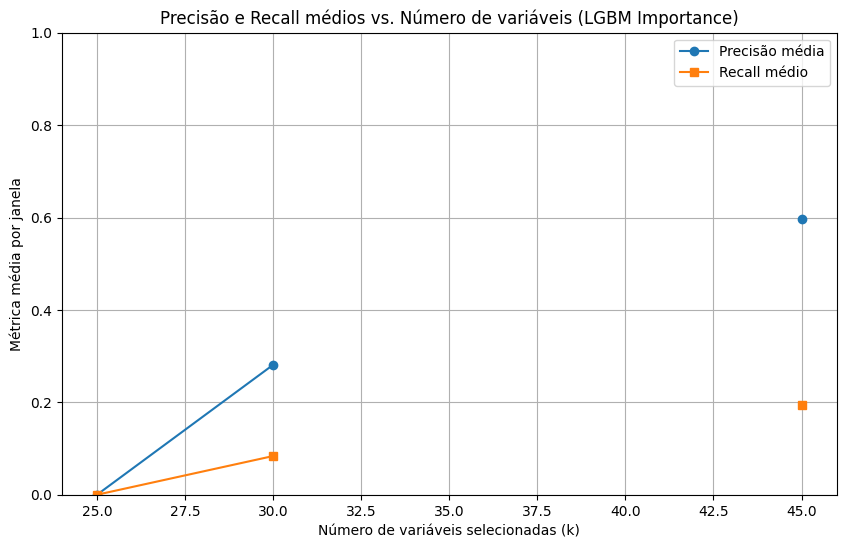

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


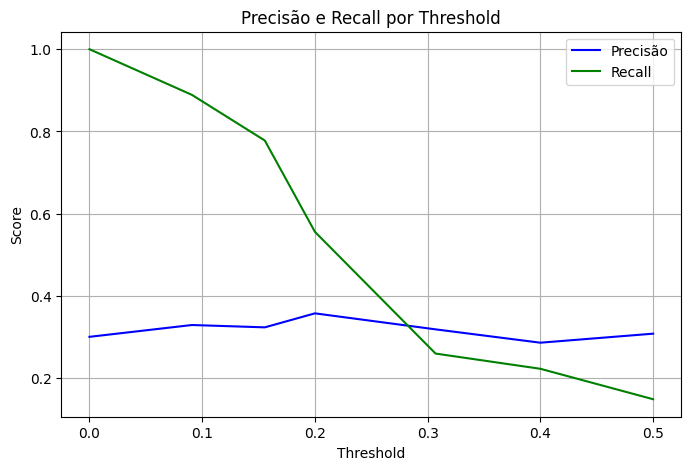

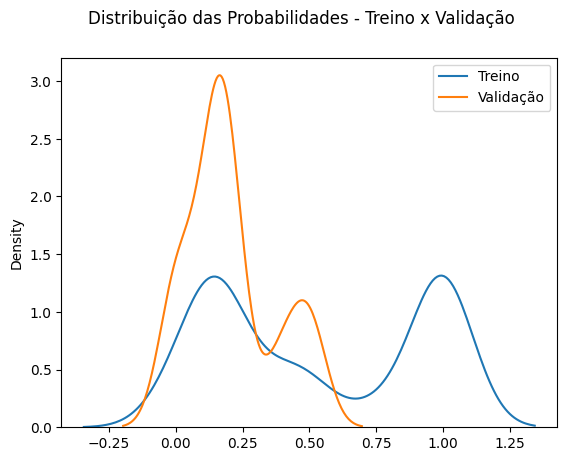

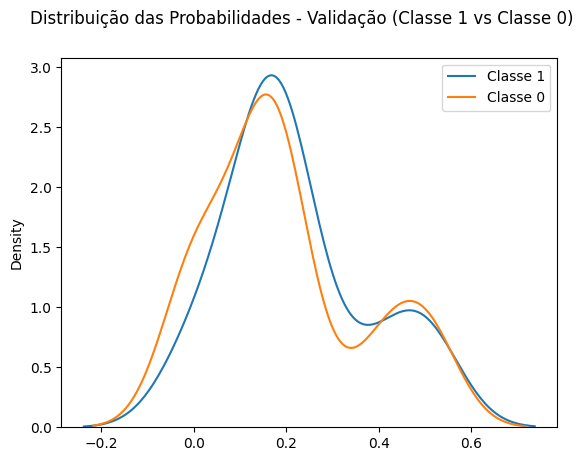

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

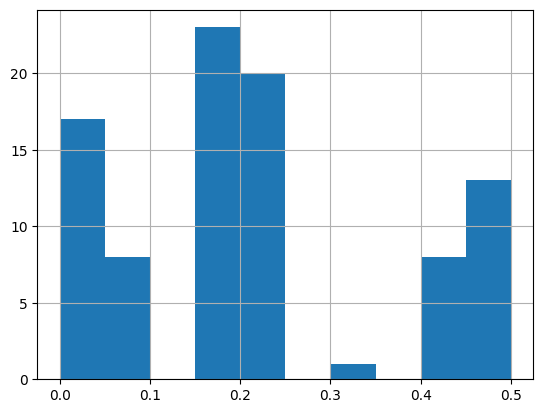

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64